In [1]:
import scipy.sparse as sp
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import time
import torch
import torch.nn.functional as F
import torch.optim as optim
import torch.nn as nn
import scvelo as scv
from sklearn.decomposition import PCA
#from utils import seed_everything, load_data, sigmoid_gumbel_sample, get_logger, makedirs, count_parameters, predict_trajectory
from parse import parser
#from model import build_model_tabular, set_cnf_options,build_model_spatial
from lib.regularization import create_regularization_fns
from train import pred_train, graph_discov
from visualize import plot_output, plot_causal_matrix
import os
from sklearn.neighbors import kneighbors_graph

In [2]:
import numpy as np
import spateo as spt
import torch
import scanpy as sc
import scvelo as scv
import anndata as ad
import pandas as pd

In [3]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.pyplot import rc_context
from matplotlib.colors import Normalize, TwoSlopeNorm
from matplotlib.cm import ScalarMappable
import matplotlib.ticker as ticker

In [4]:
import numpy as np
import spateo as spt
import torch
import scanpy as sc
import scvelo as scv
import anndata as ad
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.pyplot import rc_context
from matplotlib.colors import Normalize, TwoSlopeNorm
from matplotlib.cm import ScalarMappable
import matplotlib.ticker as ticker
import scipy.sparse as sp
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import time
import torch
import torch.nn.functional as F
import torch.optim as optim
import torch.nn as nn
import scvelo as scv
from sklearn.decomposition import PCA
from utils import seed_everything, load_data, sigmoid_gumbel_sample, get_logger, makedirs, count_parameters
from parse import parser
from model import build_model_tabular, set_cnf_options
from lib.regularization import create_regularization_fns
from train import pred_train, graph_discov
from visualize import plot_output, plot_causal_matrix
import os
from sklearn.neighbors import kneighbors_graph
import numpy as np
import torch
import random

In [ ]:
adata= spt.read_h5ad('./sim_dataset/sim2_dynamic_rates_aligned.h5ad')
adata

AnnData object with n_obs × n_vars = 4138 × 3
    obs: 'time', 'true_growth_rate', 'true_death_rate', 'true_net_growth', 'time_point'
    obsm: 'spatial', 'spatial_aligned_gt'

In [ ]:
import torch
exp_model_path = './sim_dataset/sim_graph_checkpt.pth'
#spatial_path = '/media/lenovo/A06B2FA1620B6FCB/pythonProject/models/Rspatial_checkpt.pth'

model = torch.load(exp_model_path, map_location=torch.device('cpu'))
#spatial_model = torch.load(spatial_path, map_location=torch.device('cpu'))


In [8]:
class GrowthNet(torch.nn.Module):
    def __init__(self):
        super().__init__()

        self.fc1 = torch.nn.Linear(4, 64)
        self.fc2 = torch.nn.Linear(64, 64)
        self.fc3 = torch.nn.Linear(64, 1)

    def forward(self, x):
        x = torch.nn.functional.leaky_relu(self.fc1(x))
        x = torch.nn.functional.leaky_relu(self.fc2(x))
        x = self.fc3(x)
        return x
growth_model_path= '/mnt/sda2/causal_1105/sim_data/grow_model_1.0.pth'
growth_model = torch.load(growth_model_path, map_location=torch.device('cpu'))


In [9]:
integral_time = list(np.unique(adata.obs['time_point']))
time_pts = range(len(integral_time))
integral_time


[0, 1, 2, 3, 4, 5]

In [ ]:
def raw_gene_space_growth(growth_model_path, device=torch.device('cpu')):
   
    growth_model = torch.load(growth_model_path, map_location=device)
    growth_model.eval()
    
    def growth(encoded_gene, t):
        
        
        if not isinstance(encoded_gene, torch.Tensor):
            encoded_gene = torch.tensor(encoded_gene, dtype=torch.float32).to(device)
        
        
        batch_size = encoded_gene.shape[0]
        time_tensor = torch.tensor(t, dtype=torch.float32).repeat(batch_size, 1).to(device)
        
        input_data = torch.cat([encoded_gene, time_tensor], axis=1)
        
        
        with torch.no_grad():
            cell_growth = growth_model(input_data)
        #g_min = torch.min(cell_growth)
        #g_max = torch.max(cell_growth)
        #cell_growth_norm = 2 * (cell_growth - g_min) / (g_max - g_min) - 1
        return cell_growth
    
    return growth

In [11]:
growth_gene = raw_gene_space_growth(growth_model_path, device=torch.device('cpu'))
#growth_gene
#velocity_T = np.zeros_like(adata.X)
#velocity_ae = np.zeros_like(adata.obsm['X_latent'])
#velocity_spatial = np.zeros_like(adata.obsm['spatial_aligned'])
cell_growth = np.zeros((adata.n_obs, 1))
#cell_growth
# compute cell RNA velocity, spatial velocity and growth


In [12]:
for i in time_pts:
    cur_cell_gene = torch.tensor(adata[adata.obs.time_point==integral_time[i], :].X, requires_grad=False, dtype=torch.float32)
    #cur_cell_spatial = torch.tensor(adata[adata.obs.time==integral_time[i], :].obsm['X_spatial'], requires_grad=False, dtype=torch.float32)

    
    cur_cell_growth = growth_gene(cur_cell_gene, integral_time[i])
    
    
    cell_growth[adata.obs.time_point==integral_time[i]] = cur_cell_growth.detach().numpy()


In [13]:
adata.obs['cell_growth'] = cell_growth.squeeze()
var_names = adata.var_names
var_names_new = [s.split("|")[0].strip() for s in list(var_names)]
adata.var_names = var_names_new
adata.var['var_names_new'] = var_names_new


In [321]:
adata

AnnData object with n_obs × n_vars = 4138 × 3
    obs: 'time', 'true_growth_rate', 'true_death_rate', 'true_net_growth', 'time_point', 'cell_growth'
    var: 'var_names_new'
    obsm: 'spatial', 'spatial_aligned_gt'

In [322]:
adata.obs['time_batch'] = ['']*adata.n_obs
adata.obs['time_batch'][adata.obs.time_point==integral_time[0]] = 0
adata.obs['time_batch'][adata.obs.time_point==integral_time[1]] = 1
adata.obs['time_batch'][adata.obs.time_point==integral_time[2]] = 2
adata.obs['time_batch'][adata.obs.time_point==integral_time[3]] = 3
adata.obs['time_batch'][adata.obs.time_point==integral_time[4]] = 4
adata.obs['time_batch'][adata.obs.time_point==integral_time[5]] = 5
adata.uns['time_batch_colors'] = ['#E74C3C', '#3498DB', '#F1C40F', '#2ECC71', '#9B59B6', "#103BE5"]


In [14]:
adata_0 = adata[adata.obs.time_point==integral_time[0], :]
adata_1 = adata[adata.obs.time_point==integral_time[1], :]
adata_2 = adata[adata.obs.time_point==integral_time[2], :]
adata_3 = adata[adata.obs.time_point==integral_time[3], :]
adata_4 = adata[adata.obs.time_point==integral_time[4], :]
adata_5 = adata[adata.obs.time_point==integral_time[5], :]


In [15]:
growth_true = adata_5.obs['true_net_growth'].values 
growth_pred = adata_5.obs['cell_growth'].values

In [342]:
import numpy as np 
import pandas as pd 
adata
growth_true = adata_5.obs['true_net_growth'].values
growth_pred = adata_5.obs['cell_growth'].values
mae = np.mean(np.abs(growth_pred- growth_true)) 
print(mae)

0.25290686259834105


In [ ]:
save_path = './sim_dataset'
## Plot the aligned data
# Set parameters
sc.set_figure_params(dpi=150, dpi_save=400, frameon=False, fontsize=8, transparent=True)
sc.settings.verbosity = 0
sc.logging.print_header()


scanpy==1.9.8 anndata==0.9.2 umap==0.5.7 numpy==1.22.4 scipy==1.9.3 pandas==1.5.3 scikit-learn==1.3.2 statsmodels==0.14.1 igraph==0.11.8 pynndescent==0.5.13


In [17]:
adata.obs['cell_growth'] = cell_growth.squeeze()


In [18]:
def load_data_from_anndata(adata, time_key='time_point', spatial_key='spatial'):
   
    
    train_time = adata.obs[time_key].unique()
    
    train_time = np.sort(train_time)
    
    # 构建 data_train 字典
    data_train = {}
    for t in train_time:
        # 选择特定时间点的细胞
        adata_t = adata[adata.obs[time_key] == t]
        
        # 获取基因表达数据
        
        gene_expr = adata_t.X
        
        # 获取空间坐标
        
        spatial_coords = adata_t.obsm[spatial_key]
            # 如果空间坐标维度大于2，取前两维
          
        # 合并数据
        cell_data = np.concatenate([gene_expr, spatial_coords], axis=1)
        
        # 转换为 PyTorch 张量
        data_train[t] = torch.tensor(cell_data, dtype=torch.float32)
    
    return data_train,train_time

# 使用函数加载数据
data_train,train_time = load_data_from_anndata(adata)
init_cell_5DPI = data_train[train_time[1]]


In [ ]:
cnf_model_path = "./sim_dataset/sim_cnf_model.pth" 
from cnf_OT import ContinuousTimeCNFGenerator
device = 'cuda' if torch.cuda.is_available() else 'cpu'
time_series_data = [adata[adata.obs['time_point'] == tp] for tp in [0,1,2,3,4,5] if len(adata[adata.obs['time_point'] == tp])>0]
cnf_generator = ContinuousTimeCNFGenerator.load_model(
        path=cnf_model_path,
        time_series_data=time_series_data,
       growth_model=growth_model,
        device=device
    )
cnf_generator.cnf_model.eval()


Time point 0: 600 cells
Time point 1: 584 cells
Time point 2: 604 cells
Time point 3: 667 cells
Time point 4: 765 cells
Time point 5: 918 cells
Initialized continuous time CNF model with 8837 parameters
Training continuous time CNF model...
CNF Training Iteration 0/1000, Loss: 0.0168
CNF Training Iteration 100/1000, Loss: 0.0142
CNF Training Iteration 200/1000, Loss: 0.0276
CNF Training Iteration 300/1000, Loss: 0.0230
CNF Training Iteration 400/1000, Loss: 0.0118
CNF Training Iteration 500/1000, Loss: 0.0064
CNF Training Iteration 600/1000, Loss: 0.0096
CNF Training Iteration 700/1000, Loss: 0.0255
CNF Training Iteration 800/1000, Loss: 0.0219
CNF Training Iteration 900/1000, Loss: 0.0235
Continuous time CNF model training completed.
Continuous time model loaded from /mnt/sda2/causal_1105/sim_cnf_model2.pth


ContinuousTimeSequentialFlow(
  (chain): ModuleList(
    (0): ContinuousTimeCNF(
      (odefunc): ContinuousTimeODEfunc(
        (diffeq): ContinuousTimeODEnet(
          (layers): ModuleList(
            (0): TimeAwareMLPLayer(
              (linear): Linear(in_features=3, out_features=64, bias=True)
            )
            (1-2): 2 x TimeAwareMLPLayer(
              (linear): Linear(in_features=65, out_features=64, bias=True)
            )
            (3): TimeAwareMLPLayer(
              (linear): Linear(in_features=65, out_features=2, bias=True)
            )
          )
          (activation_fns): ModuleList(
            (0-2): 3 x Tanh()
          )
        )
      )
    )
  )
)

In [21]:
from sklearn.preprocessing import StandardScaler
import torch
import numpy as np
from CNF5 import _disperse_points

def evolution_forward(init_cell, model, growth_model, init_time, end_time, 
                      delta_t=0.1, trained_scaler=None, max_cells=20000):  # 移除init_cell_type参数
    def growth(x, delta_t, growth_model, t, cur_cell_id, sigma_d=0.00001):
        # 1. 分离基因表达（前N-2列）和坐标（最后2列），并统一设备
        device = x.device  # 跟随输入x的设备（避免CPU/GPU不匹配）
        x_np = x.detach().cpu().numpy()
        y_np = x_np[:, 0:-2]  # 基因表达部分
        coords_np = x_np[:, -2:]  # 坐标部分
        
        # 2. 用训练好的scaler标准化基因表达（关键修改：不再实时拟合）
        y_transformed = torch.tensor(y_np, dtype=torch.float32, device=device)
        coords = torch.tensor(coords_np, dtype=torch.float32, device=device)
        
        cell_number = x.shape[0]
        x_growth = []
        y_growth = []
        new_cell_id = []
        
        # 3. 时间张量处理（修复原代码view(-1,1)可能的维度错误，确保输入时间为标量t）
        if not isinstance(t, (int, float)):
            t = t.item()  # 若t是张量，转为标量
        t_tensor = torch.tensor(t, dtype=torch.float32, device=device).view(1, 1)
        t_tensor = t_tensor.repeat(cell_number, 1)  # 形状：(cell_number, 1)
        
        # 4. 生长率预测与约束（限制生长率上限，避免分裂概率>1）
        combined_input = torch.cat([y_transformed, t_tensor], axis=1)
        g = growth_model(combined_input)
        for i in range(cell_number):
            g_i = g[i, :]  # 转为标量，避免维度问题
            temp = np.random.rand()
           
            if g_i > 1.18 and temp < (g_i * delta_t):
                # 分裂：保留母细胞+新增子细胞（子细胞ID加后缀区分）
                x_growth.append(y_transformed[i, :])
                y_growth.append(coords[i, :])
                new_cell_id.append(cur_cell_id[i])  # 母细胞ID
                # 子细胞：基因和坐标加小噪声（控制变异程度）
                new_gene = y_transformed[i, :] + sigma_d * torch.randn_like(y_transformed[i, :])
                offset = np.random.normal(0, 0.1, size=2)
                new_coord = coords[i, :] + offset
                x_growth.append(new_gene)
                y_growth.append(new_coord)
                new_cell_id.append(cur_cell_id[i])  # 子细胞ID
            elif g_i >1.18 and temp > (g_i * delta_t):
                x_growth.append(y_transformed[i, :])
                y_growth.append(coords[i, :])
                new_cell_id.append(cur_cell_id[i])
            elif g_i <1.18 and temp > (-g_i * delta_t):
                # 存活：仅保留母细胞
                x_growth.append(y_transformed[i, :])
                y_growth.append(coords[i, :])
                new_cell_id.append(cur_cell_id[i])
        
        # 6. 细胞数量上限控制（模拟环境承载）
        if len(x_growth) > max_cells:
            keep_idx = np.random.choice(len(x_growth), max_cells, replace=False)
            x_growth = [x_growth[idx] for idx in keep_idx]
            new_cell_id = [new_cell_id[idx] for idx in keep_idx]
        
        # 7. 处理无细胞存活的极端情况（避免后续报错）
        if not x_growth:
            return x, cur_cell_id
        cur_gene = torch.vstack(x_growth).type(torch.float32)
        cur_coord = torch.vstack(y_growth).type(torch.float32)
        cur_cell = torch.cat([cur_gene, cur_coord], dim=1)
        
        # 8. 更新当前细胞状态
        return cur_cell, new_cell_id
    
    # ---------------------- 主流程修改（移除cell_type） ----------------------
    # 1. 生成0.1步长的时间序列（确保包含end_time，避免浮点数误差）
    time_point = np.arange(init_time, end_time + delta_t, delta_t)
    time_point = np.round(time_point, 1)  # 如0.0,0.1,0.2,...,2.0
    time_point = np.unique(time_point)  # 去重（避免end_time重复）
    time_step = time_point[1:] - time_point[0:-1]
    
    # 2. 初始化存储列表（删除all_cell_type）
    all_time_point = list(time_point)
    all_exp = []
    all_spa = []
    all_cell_id = []
    
    cur_cell = init_cell
    # 确保初始细胞在正确设备上（与模型一致）
    device = next(growth_model.parameters()).device
    cur_cell = cur_cell.to(device, dtype=torch.float32)
    print(f"初始细胞形状: {cur_cell.shape}, 设备: {device}")
    
    # 3. 初始化细胞ID（删除cell_type相关初始化）
    cur_cell_id = [f"cell_{i}" for i in range(cur_cell.shape[0])]  # 字符串ID，便于区分母子细胞
    
    # 4. 时间步迭代预测
    for i in range(len(time_point)):
        # 存储当前时间点结果（删除all_cell_type.append）
        all_exp.append(cur_cell[:, 0:-2].detach().cpu().numpy())
        all_spa.append(cur_cell[:, -2:].detach().cpu().numpy())
        all_cell_id.append(cur_cell_id)
        
        # 若到达最后一个时间点，停止迭代（删除cur_cell_type更新）
        if i < len(time_step):
            # 5. 生长模型处理（传入训练好的scaler）
            cur_cell, cur_cell_id = growth(
                x=cur_cell,
                delta_t=time_step[i],
                growth_model=growth_model,
                t=time_point[i],
                cur_cell_id=cur_cell_id,
                sigma_d=0.00001
            )
        
            # 6. 基因表达模型更新（限制更新幅度，避免基因值异常）
            z_gene = cur_cell[:, 0:-2]
            logpz = None
            integration_times = torch.tensor([0.0, time_step[i]], dtype=z_gene.dtype, device=device)
            zero = torch.zeros(z_gene.shape[0], 1, device=device)
            gene_output, logpz = model.chain[0](z_gene, zero, integration_times=integration_times)
            # 限制基因表达更新范围（避免数值爆炸）
            cur_cell[:, 0:-2] = gene_output
        
            # 7. 空间模型更新（确保坐标更新后维度正确）
            z_spatial = cur_cell[:, -2:]
        
            scaler = cnf_generator.coord_scalers[2]
            spatial = z_spatial.detach().cpu().numpy()
            z_spatial_prep = scaler.transform(spatial)
            z_spatial_prep = torch.tensor(z_spatial_prep, dtype=z_gene.dtype, device=device)
            
            spatial_output = cnf_generator.cnf_model(z_spatial_prep, integration_times=integration_times)
            predicted_coords_scaled = spatial_output[1].cpu().numpy()
        
            # 应用分散处理
            predicted_coords_scaled = _disperse_points(predicted_coords_scaled, min_dist=0.03, max_iter=30)
            spatial = torch.tensor(predicted_coords_scaled, dtype=z_gene.dtype, device=device)
            predicted_coords = scaler.inverse_transform(spatial)

            # 确保预测坐标是2维（n_cells, 2）
            if predicted_coords.shape[1] != 2:
                raise ValueError(f"空间模型输出坐标维度错误，应为2维，实际为{predicted_coords.shape[1]}维")
            cur_cell[:, -2:] = torch.tensor(predicted_coords, dtype=cur_cell.dtype, device=device)
    
    # 返回值删除all_cell_type
    return all_exp, all_spa, all_cell_id, all_time_point

In [34]:
import anndata as ad
import pandas as pd
import numpy as np

# ---------------------- 1. 修正模型调用（适配无细胞类型/空间模型的evolution_forward） ----------------------
# from 2DPI to 3.5DPI
init_cell_2DPI = data_train[train_time[4]]
growth_model.eval()  # 生长模型设为评估模式

common_initial_time_point = 0
init_time =4- common_initial_time_point
end_time = 5 #- common_initial_time_point

# 关键修改：
# 1. 补充必传的growth_model参数（之前遗漏）
# 2. 适配返回值：all_exp, all_spa, all_cell_id, all_time_point（无all_cell_type）
# 3. 移除spatial_model（若函数不需要则不传）
all_exp, all_spa, all_cell_id, all_time_point = evolution_forward(
    init_cell=init_cell_2DPI,
    model=model,
    growth_model=growth_model,  # 补充必传的生长模型参数
    init_time=init_time,
    end_time=end_time,
    delta_t=0.1
)

# ---------------------- 2. 提取最后一个时间点的数据 ----------------------
# 最后一个时间点的基因表达（n_cells, n_genes）
final_gene_expr = all_exp[-1]  # 核心数据：基因表达
# 最后一个时间点的细胞ID（可选，作为索引）
final_cell_id = all_cell_id[-1]

# ---------------------- 3. 构建AnnData对象（仅含基因表达+细胞ID，无细胞类型） ----------------------
# 初始化AnnData：X为基因表达数据，obs索引为细胞ID
adata_St54 = ad.AnnData(
    X=final_gene_expr,  # 基因表达作为核心矩阵
    obs=pd.DataFrame(index=final_cell_id)  # 细胞ID作为观测索引
)

# ---------------------- 4. 可选：添加空间坐标（若有） ----------------------
# 若all_spa有值（空间坐标），添加到obsm（保持格式兼容）

final_spatial = all_spa[-1]
adata_St54.obsm['spatial'] = final_spatial  # 空间坐标
    #adata_St54.obsm['X_latent'] = final_gene_expr  # 保留原latent（基因表达）

# ---------------------- 5. 可选：添加时间相关元信息 ----------------------


# ---------------------- 6. 验证与保存 ----------------------
print(f"保存的AnnData形状：{adata_St54.shape}")  # (细胞数, 基因数)
# 移除细胞类型分布打印（无细胞类型）
print(f"最后一个时间点的细胞数量：{len(final_cell_id)}")

# 保存为h5ad文件
#adata_St54.write_h5ad("predicted_final_timepoint1.h5ad")
#print("AnnData文件已保存为 predicted_final_timepoint1.h5ad")

# 绘图：若plot_after_alignment_scanpy依赖细胞类型，需调整（比如只画空间分布/基因表达）
# 注：若绘图函数必须要细胞类型，需注释/修改该函数
# plot_after_alignment_scanpy(adata_St54, figsize=(6, (5*2/3)), pointsize=8, title='St49', show_legend=False,save_path='/media/lenovo/A06B2FA1620B6FCB/pythonProject/results/tmp/embry2/mouse/St49.pdf')

初始细胞形状: torch.Size([765, 5]), 设备: cpu
ODE solver error: Expected all tensors to be on the same device, but found at least two devices, cuda:0 and cpu! (when checking argument for argument mat1 in method wrapper_CUDA_addmm)
ODE solver error: Expected all tensors to be on the same device, but found at least two devices, cuda:0 and cpu! (when checking argument for argument mat1 in method wrapper_CUDA_addmm)
ODE solver error: Expected all tensors to be on the same device, but found at least two devices, cuda:0 and cpu! (when checking argument for argument mat1 in method wrapper_CUDA_addmm)
ODE solver error: Expected all tensors to be on the same device, but found at least two devices, cuda:0 and cpu! (when checking argument for argument mat1 in method wrapper_CUDA_addmm)
ODE solver error: Expected all tensors to be on the same device, but found at least two devices, cuda:0 and cpu! (when checking argument for argument mat1 in method wrapper_CUDA_addmm)
ODE solver error: Expected all tensor

In [129]:
X_pred=adata_St54.X

X_true=adata_5.X
import numpy as np
import ot 
def wasserstein_2_distance(X_pred, X_true): 
    n_pred = X_pred.shape[0] 
    n_true = X_true.shape[0] # Uniform weights (probability distributions) 
    a = np.ones(n_pred) / n_pred 
    b = np.ones(n_true) / n_true # Squared Euclidean cost matrix 
    M = ot.dist(X_pred, X_true, metric='euclidean') ** 2 # Compute optimal transport cost 
    W2_squared = ot.emd2(a, b, M) 
    return np.sqrt(W2_squared)  
wasserstein_2_distance(X_pred, X_true)

0.5370441413021472

In [33]:
import numpy as np
import ot
from scipy.spatial.distance import cdist

def w2_distance_gene_and_space_with_error(
    X_pred_gene: np.ndarray,
    X_pred_space: np.ndarray,
    X_true_gene: np.ndarray,
    X_true_space: np.ndarray,
    w: float = 0.9,
    sample_size: int = 10000,
    n_repeats: int = 5,
) -> tuple:
    """
    联合空间（基因+空间）的 W2 距离，并返回多次子采样的均值和标准差。
    """
    n = X_pred_gene.shape[0]
    m = X_true_gene.shape[0]
    w2_list = []

    for _ in range(n_repeats):
        # 随机子采样
        if n > sample_size:
            idx_pred = np.random.choice(n, sample_size, replace=False)
        else:
            idx_pred = np.arange(n)
        if m > sample_size:
            idx_true = np.random.choice(m, sample_size, replace=False)
        else:
            idx_true = np.arange(m)

        X_pred_gene_sub = X_pred_gene[idx_pred]
        X_pred_space_sub = X_pred_space[idx_pred]
        X_true_gene_sub = X_true_gene[idx_true]
        X_true_space_sub = X_true_space[idx_true]

        a = np.ones(X_pred_gene_sub.shape[0]) / X_pred_gene_sub.shape[0]
        b = np.ones(X_true_gene_sub.shape[0]) / X_true_gene_sub.shape[0]

        M_gene = cdist(X_pred_gene_sub, X_true_gene_sub, metric="sqeuclidean")
        M_space = cdist(X_pred_space_sub, X_true_space_sub, metric="sqeuclidean")
        M = w * M_gene + (1 - w) * M_space

        W2_sq = ot.emd2(a, b, M)   # 精确 W2
        w2_list.append(np.sqrt(W2_sq))

    return np.mean(w2_list), np.std(w2_list)
#scale_factor = adata.uns.get('spatial_scale_factor')

mean_w2, std_w2 = w2_distance_gene_and_space_with_error(
    X_pred_gene=adata_St54.X,
    X_pred_space=adata_St54.obsm['spatial'] ,
    X_true_gene=adata_2.X,
    X_true_space=adata_2.obsm['spatial'] ,
    w=0.9,
    sample_size=594,
    n_repeats=5
)
print(f"W2 = {mean_w2:.6f} ± {std_w2:.6f}")

W2 = 0.743761 ± 0.001638


In [35]:
import numpy as np
import anndata as ad
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.spatial import cKDTree, distance
from sklearn.neighbors import NearestNeighbors

# 设置中文支持


def compute_local_density(coords, k=10):
    """计算基于k近邻的局部密度权重"""
    tree = cKDTree(coords)
    dists, _ = tree.query(coords, k=k+1)
    avg_dists = np.mean(dists[:, 1:], axis=1)
    densities = 1 / (avg_dists + 1e-6)
    return densities / np.max(densities)

def improved_spatial_rmse(adata_pred, adata_true, resolution=1.0):
    """
    改进的空间RMSE计算，解决密度不匹配问题
    """
    pred_coords = adata_pred.obsm['spatial']
    true_coords = adata_true.obsm['spatial_aligned_gt']
    
    # 密度自适应匹配
    nbrs = NearestNeighbors(n_neighbors=1).fit(true_coords)
    distances, indices = nbrs.kneighbors(pred_coords)
    matched_true_coords = true_coords[indices[:, 0]]
    
    # 计算局部密度权重 - 关键修复：为匹配点计算权重
    # 使用匹配的真实点坐标计算密度权重，而不是全部真实点
    density_weights = compute_local_density(matched_true_coords)
    
    # 计算加权距离
    dists = np.linalg.norm(pred_coords - matched_true_coords, axis=1)
    max_migration = 50.0 / resolution
    constrained_dists = np.minimum(dists, max_migration)
    
    # 确保形状一致
    assert constrained_dists.shape == density_weights.shape, \
        f"形状不匹配: 距离数组{constrained_dists.shape}, 权重数组{density_weights.shape}"
    
    # 计算加权RMSE
    weighted_mse = np.average(constrained_dists**2, weights=density_weights)
    weighted_rmse = np.sqrt(weighted_mse)
    
    return weighted_rmse, matched_true_coords

def calculate_avg_spacing(coords):
    dists = distance.pdist(coords)
    return np.median(dists)

# 使用示例
if __name__ == "__main__":
    # 生成示例数据
    np.random.seed(42)
    
    import squidpy as sq
    import scanpy as sc
    
    # 加载数据
    
    pred_coords = adata_St54.obsm['spatial']  # 形状 (n_cells, 2)
    #shift_value1 = 180  
    #shift_value2 = -20
    #pred_coords[:,0]+=shift_value1
    #pred_coords[:,1]+=shift_value2
    #y_min, y_max = -100, -70
    #mask = (
  # (pred_coords[:, 1] >= y_min) &  # X轴下限
   # (pred_coords[:, 1] <= y_max)
#)

# 应用筛选
    #pred_coords = pred_coords[mask]
    #pred_coords[:,1]-=shift_value2
    #adata2 = sc.read_h5ad('/media/lenovo/A06B2FA1620B6FCB/pythonProject/data/DevelopmentTime5.h5ad')
    #adata2
    #adata1_sub=adata2[adata2.obs['time']=='3.3hpf']
    #adata2_sub=adata2[adata2.obs['time']=='5.25hpf']
    #adata3_sub=adata2[adata2.obs['time']=='10hpf']
    #adata4_sub=adata[adata.obs['time']==1]
    #adata5_sub=adata2[adata2.obs['time']=='18hpf']
    #adata6_sub=adata2[adata2.obs['time']=='24hpf']
    #adata_true=adata_0
    #adata_true = sc.read_h5ad("/media/lenovo/A06B2FA1620B6FCB/pythonProject/data/DevelopmentTime5.h5ad")
    true_coords = adata_5.obsm['spatial']

    # 计算平均间距
    avg_spacing = calculate_avg_spacing(true_coords)
    print(f"average spacing: {avg_spacing:.2f}")
    
    # 计算改进的RMSE
    rmse, matched_coords = improved_spatial_rmse(
        adata_St54, 
        adata_5,
        resolution=0.5
    )
    
    print(f"RMSE: {rmse:.4f} ")

average spacing: 1.44
RMSE: 0.5150 


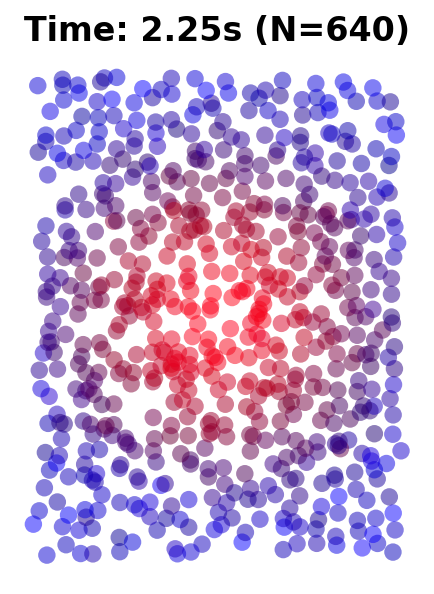

In [ ]:
# 关键：启用Notebook内嵌显示（必须放在最开头）
%matplotlib inline  
import matplotlib.pyplot as plt
import numpy as np
import anndata as ad  # 确保导入你的数据依赖

# ===================== 绘制单个时间点的图（Notebook内嵌显示） =====================
plt.figure(figsize=(5, 4))  # 单图尺寸
target_time = 2.25
subset = adata_St54

# 2. 提取坐标和基因表达
coords = subset.obsm['spatial']
genes = subset.X

# 3. 颜色映射（Red vs Blue）
r_val = genes[:, 0] / (np.percentile(genes[:, 0], 99) + 0.01)
b_val = genes[:, 1] / (np.percentile(genes[:, 1], 99) + 0.01)
r_val = np.clip(r_val, 0, 1)
b_val = np.clip(b_val, 0, 1)

colors = np.zeros((len(coords), 3))
colors[:, 0] = r_val  # 红色通道
colors[:, 2] = b_val  # 蓝色通道

# 4. 绘制散点图
plt.scatter(
    coords[:, 0], coords[:, 1], 
    c=colors, 
    s=70,          # 点大小
    alpha=0.5,     # 透明度
    edgecolors='none'  # 无边框
)

# 5. 标题和样式
plt.title(f"Time: {target_time}s (N={len(coords)})", fontsize=16, fontweight='bold')
plt.axis('off')  # 关闭坐标轴
plt.gca().set_aspect('equal')  # 等比例显示
plt.tight_layout()  # 紧凑布局
plt.savefig(
    "./sim_dataset/pred_t1.25.pdf",  # 保存的文件名
    dpi=300,                           # 分辨率（矢量图dpi不影响清晰度，仅影响嵌入的位图）
    bbox_inches='tight',               # 裁剪多余空白
    pad_inches=0.1,                    # 保留少量边距，避免标题被切
    format='pdf'                       # 指定格式为PDF（可省略，文件名带.pdf即可）
)
# 关键：Notebook中必须执行plt.show()（即使加了%matplotlib inline）
plt.show()  

# 可选：同时保存图片到Notebook所在目录（方便后续下载）
#plt.savefig(f"single_timepoint_{target_time}s.png", dpi=300, bbox_inches='tight')

In [10]:
plt.figure(figsize=(15, 9))
times = adata.obs['time_point'].unique()

for i, t in enumerate(times):
    subset = adata[adata.obs['time_point'] == t]
    coords = subset.obsm['spatial']
    genes = subset.X
    
    # 颜色映射: Red vs Blue
    r_val = genes[:, 0] / (np.percentile(genes[:, 0], 99) + 0.01)
    b_val = genes[:, 1] / (np.percentile(genes[:, 1], 99) + 0.01)
    
    r_val = np.clip(r_val, 0, 1)
    b_val = np.clip(b_val, 0, 1)
    
    colors = np.zeros((len(coords), 3))
    colors[:, 0] = r_val
    colors[:, 2] = b_val
    
    ax = plt.subplot(2, 3, i+1)
    
    # 调整 s=80, alpha=0.5
    # 初始 600 个点，随着时间推移可能会增长到 1000+
    ax.scatter(coords[:, 0], coords[:, 1], c=colors, s=70, alpha=0.5, edgecolors='none')
    
    ax.set_title(f"Time: {t}s (N={len(coords)})", fontsize=14, fontweight='bold')
    ax.axis('off')
    ax.set_aspect('equal')

plt.suptitle("Invasion Model with Cell Growth (N changes over time)", fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:

 
import matplotlib.pyplot as plt
import numpy as np

# ===================== 绘图+保存PDF =====================
plt.figure(figsize=(15, 9))
times = adata.obs['time_point'].unique()

# 确保子图布局适配（2行3列，若时间点超过6个需调整行列数）
assert len(times) <= 6, "时间点数量超过6个，需修改subplot行列数（如3行2列）"

for i, t in enumerate(times):
    subset = adata[adata.obs['time_point'] == t]
    coords = subset.obsm['spatial']
    genes = subset.X
    
    
    r_val = genes[:, 0] / (np.percentile(genes[:, 0], 99) + 0.01)
    b_val = genes[:, 1] / (np.percentile(genes[:, 1], 99) + 0.01)
    r_val = np.clip(r_val, 0, 1)
    b_val = np.clip(b_val, 0, 1)
    
    colors = np.zeros((len(coords), 3))
    colors[:, 0] = r_val
    colors[:, 2] = b_val
    
    ax = plt.subplot(2, 3, i+1)
    ax.scatter(coords[:, 0], coords[:, 1], c=colors, s=70, alpha=0.5, edgecolors='none')
    ax.set_title(f"Time: {t}s (N={len(coords)})", fontsize=14, fontweight='bold')
    ax.axis('off')
    ax.set_aspect('equal')

# 总标题
plt.suptitle("Invasion Model with Cell Growth (N changes over time)", fontsize=16, y=0.98)  # 调整y轴避免裁剪


# bbox_inches='tight' 裁剪空白，pad_inches=0.1 保留少量边距
plt.savefig(
    "./sim_dataset/real_invasion_model_G.pdf",  # 保存的文件名
    dpi=300,                           # 分辨率（矢量图dpi不影响清晰度，仅影响嵌入的位图）
    bbox_inches='tight',               # 裁剪多余空白
    pad_inches=0.1,                    # 保留少量边距，避免标题被切
    format='pdf'                       # 指定格式为PDF（可省略，文件名带.pdf即可）
)

# 紧凑布局（放在savefig前，避免布局错乱）
plt.tight_layout(rect=[0, 0, 1, 0.95])  # rect调整布局，给suptitle留空间
plt.show()  # Jupyter中显示图片

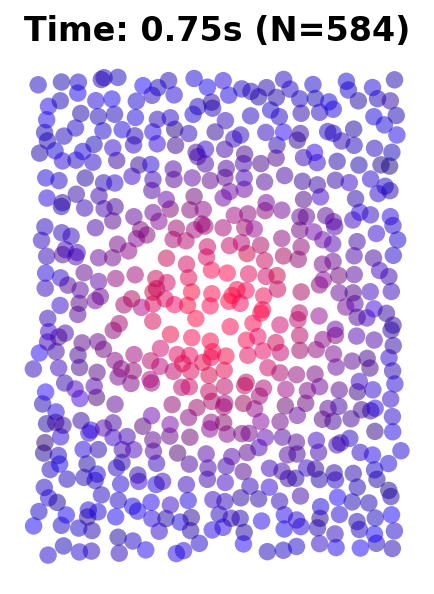

In [ ]:

%matplotlib inline  
import matplotlib.pyplot as plt
import numpy as np
import anndata as ad  # 确保导入你的数据依赖

# ===================== 绘制单个时间点的图（Notebook内嵌显示） =====================
plt.figure(figsize=(5, 4))  # 单图尺寸
target_time = 0.75
subset = adata_St54

# 2. 提取坐标和基因表达
coords = subset.obsm['spatial']
genes = subset.X

# 3. 颜色映射（Red vs Blue）
r_val = genes[:, 0] / (np.percentile(genes[:, 0], 99) + 0.01)
b_val = genes[:, 1] / (np.percentile(genes[:, 1], 99) + 0.01)
r_val = np.clip(r_val, 0, 1)
b_val = np.clip(b_val, 0, 1)

colors = np.zeros((len(coords), 3))
colors[:, 0] = r_val  
colors[:, 2] = b_val  

# 4. 绘制散点图
plt.scatter(
    coords[:, 0], coords[:, 1], 
    c=colors, 
    s=70,          
    alpha=0.5,     
    edgecolors='none'  
)

# 5. 标题和样式
plt.title(f"Time: {target_time}s (N={len(coords)})", fontsize=16, fontweight='bold')
plt.axis('off')  
plt.gca().set_aspect('equal')  
plt.tight_layout()  
plt.savefig(
    "./sim_dataset/pred_t0.75.pdf",  
    dpi=300,                           
    bbox_inches='tight',               
    pad_inches=0.1,                    
    format='pdf'                       
)

plt.show()  

